# Tomato Pest Classification with Two Dense Layers

**DSA Course — Homework (final session presentation)**

**Task:** Design a neural network with **two Dense layers** that classifies images of **8 common tomato pests**.

**Evaluation metrics:** Accuracy, F1 Score and AUC.

This notebook follows the same workflow as *Designing a Neural Network* (Fashion-MNIST lab):
define the task → load data → prepare data → design the model → configure → train → evaluate → improve.

> Run in Google Colab (**Runtime → Change runtime type → T4 GPU** recommended) or locally. Run the cells from top to bottom. The dataset downloads automatically.

## 1. The dataset

**A database of eight common tomato pest images** — Huang, M.-L. & Chuang, T.-C. (2020), Mendeley Data, V1.
DOI: [10.17632/s62zm6djd2.1](https://data.mendeley.com/datasets/s62zm6djd2/1) — publicly available (CC BY 4.0).

| Code | Pest (scientific name) | Common name |
|---|---|---|
| BA | *Bemisia argentifolii* | Silverleaf whitefly |
| HA | *Helicoverpa armigera* | Cotton bollworm / tomato fruitworm |
| MP | *Myzus persicae* | Green peach aphid |
| SE | *Spodoptera exigua* | Beet armyworm |
| SL | *Spodoptera litura* | Tobacco cutworm |
| TP | *Thrips palmi* | Melon thrips |
| TU | *Tetranychus urticae* | Two-spotted spider mite |
| ZC | *Zeugodacus cucurbitae* | Melon fly |

The dataset has **609 original images** (299 × 299 RGB). The authors also publish an "enhanced" version with 4,263 images, but those are rotated/flipped copies of the same 609 photos.
We use the **original** images and split them ourselves. Otherwise, copies of the same photo could appear in both the training and test sets, and the test score would look better than it really is.

## 2. Import the libraries

In [1]:
%pip install -q py7zr


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: /private/tmp/claude-501/-Users-gilberttuyishime-Documents-Personal-Document-mount-kigali-Semester-3-AI/ec49c841-239d-4606-a087-43593f54dbb1/scratchpad/venv/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import py7zr
from PIL import Image
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
tf.keras.utils.set_random_seed(SEED)  # makes results repeatable

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

## 3. Download and load the dataset

The archive (~9 MB) is downloaded from Mendeley Data and extracted once. Each class is stored in its own folder (BA, HA, MP, ...).

In [3]:
URL = ("https://data.mendeley.com/public-files/datasets/s62zm6djd2/files/"
       "e2e3fc63-2eb3-4860-aec7-4089731ddb2e/file_downloaded")
ARCHIVE = "tomato_pests.7z"
DATA_DIR = "tomato_pests"
IMAGE_ROOT = os.path.join(DATA_DIR, "Original image of tomato pest")

if not os.path.isdir(IMAGE_ROOT):
    print("Downloading dataset...")
    request = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request) as response, open(ARCHIVE, "wb") as f:
        f.write(response.read())
    with py7zr.SevenZipFile(ARCHIVE) as archive:
        archive.extractall(DATA_DIR)
print("Images are in:", IMAGE_ROOT)

Images are in: tomato_pests/Original image of tomato pest


In [4]:
class_codes = sorted(d for d in os.listdir(IMAGE_ROOT) if os.path.isdir(os.path.join(IMAGE_ROOT, d)))
class_names = {
    "BA": "Whitefly (B. argentifolii)", "HA": "Bollworm (H. armigera)",
    "MP": "Aphid (M. persicae)",        "SE": "Beet armyworm (S. exigua)",
    "SL": "Cutworm (S. litura)",        "TP": "Thrips (T. palmi)",
    "TU": "Spider mite (T. urticae)",   "ZC": "Melon fly (Z. cucurbitae)",
}
num_classes = len(class_codes)

IMG_SIZE = 160  # images are resized from 299x299 to 160x160 to save memory and time

images, labels = [], []
for label, code_name in enumerate(class_codes):
    folder = os.path.join(IMAGE_ROOT, code_name)
    for file in sorted(os.listdir(folder)):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            img = Image.open(os.path.join(folder, file)).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
            images.append(np.array(img, dtype=np.uint8))
            labels.append(label)

X = np.stack(images)
y = np.array(labels)
print("Images:", X.shape, " Labels:", y.shape)
print("Classes:", class_codes)

Images: (609, 160, 160, 3)  Labels: (609,)
Classes: ['BA', 'HA', 'MP', 'SE', 'SL', 'TP', 'TU', 'ZC']


### Inspect the data

Two things to check: what the images look like, and whether the classes are balanced.

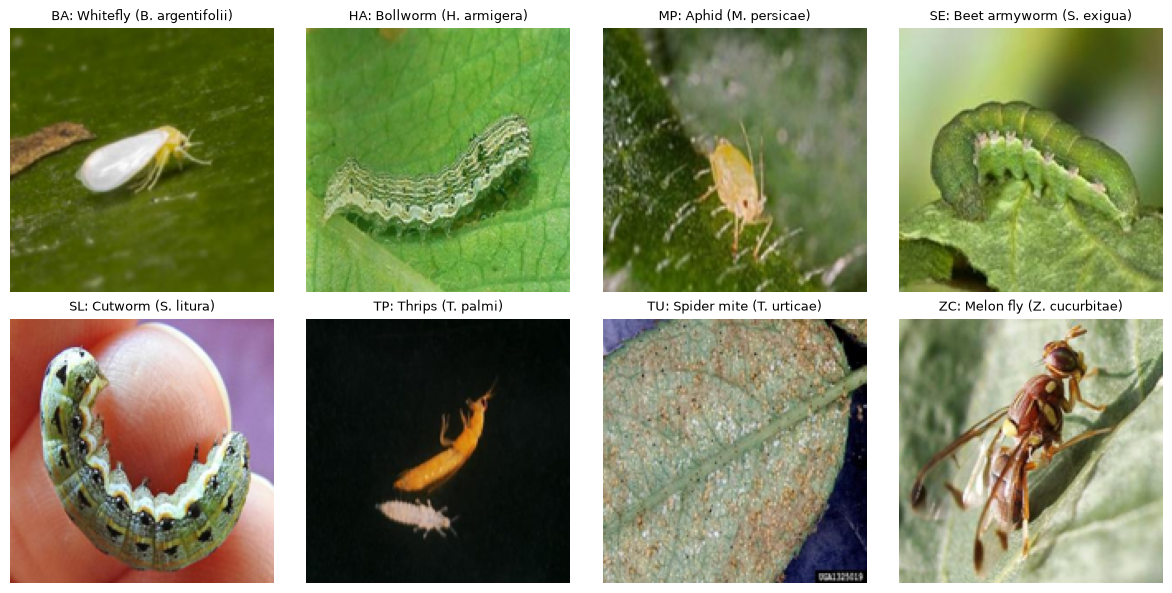

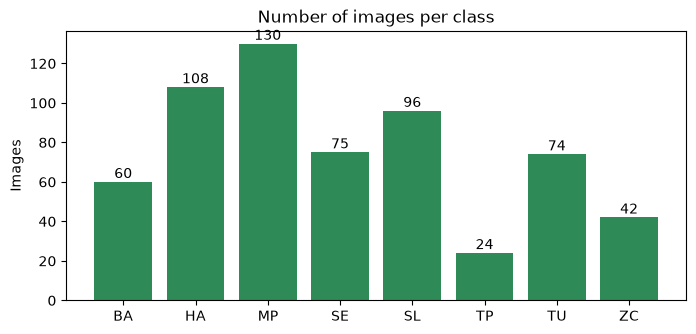

In [5]:
plt.figure(figsize=(12, 6))
for i, code_name in enumerate(class_codes):
    idx = np.where(y == i)[0][0]
    plt.subplot(2, 4, i + 1)
    plt.imshow(X[idx])
    plt.title(f"{code_name}: {class_names[code_name]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

counts = np.bincount(y)
plt.figure(figsize=(8, 3.5))
plt.bar(class_codes, counts, color="seagreen")
for i, c in enumerate(counts):
    plt.text(i, c + 2, str(c), ha="center")
plt.title("Number of images per class")
plt.ylabel("Images")
plt.show()

The classes are **unbalanced**: from 24 images (Thrips) to 130 (Aphid). Because of this:
- We split the data with **stratification**, so every split keeps the same class proportions.
- We use **class weights** during training, so rare classes count more.
- We report **macro F1**, which treats every class equally. Accuracy alone can hide poor results on small classes.

## 4. Prepare the data

Split: **70% training**, **15% validation** (for monitoring training), **15% test** (only used for the final evaluation).

In [6]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape[0], " Validation:", X_val.shape[0], " Test:", X_test.shape[0])

# One-hot labels are needed for the Keras F1Score and AUC metrics
y_train_oh = tf.keras.utils.to_categorical(y_train, num_classes)
y_val_oh = tf.keras.utils.to_categorical(y_val, num_classes)
y_test_oh = tf.keras.utils.to_categorical(y_test, num_classes)

weights = compute_class_weight("balanced", classes=np.arange(num_classes), y=y_train)
class_weight = dict(enumerate(weights))
print("Class weights:", {class_codes[k]: round(float(v), 2) for k, v in class_weight.items()})

Train: 426  Validation: 91  Test: 92
Class weights: {'BA': 1.27, 'HA': 0.7, 'MP': 0.59, 'SE': 1.02, 'SL': 0.79, 'TP': 3.13, 'TU': 1.02, 'ZC': 1.84}


## 5. Evaluation metrics

| Metric | What it measures | Why it is useful here |
|---|---|---|
| **Accuracy** | Fraction of images classified correctly | Easy to understand, but can be misleading with unbalanced classes |
| **F1 Score** | Harmonic mean of precision and recall, per class. **Macro** F1 averages over classes equally | Shows whether the model also works on rare pests (e.g., Thrips) |
| **AUC** | Area under the ROC curve: how well the predicted probabilities rank the correct class above the others (1.0 = perfect, 0.5 = random). Multi-class: one-vs-rest, macro average | Measures the quality of the probabilities, not only the final decision |

The function below computes all three on any dataset. We use it for every model so the comparison is fair.

In [ ]:
def evaluate(model, X_data, y_true, name):
    probs = model.predict(X_data, verbose=0)
    preds = probs.argmax(axis=1)
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, preds),
        "F1 (macro)": f1_score(y_true, preds, average="macro"),
        "F1 (weighted)": f1_score(y_true, preds, average="weighted"),
        "AUC (macro, OvR)": roc_auc_score(y_true, probs, multi_class="ovr", average="macro"),
    }
    for k, v in results.items():
        print(f"{k:18s}: {v:.4f}" if k != "Model" else f"=== {v} ===")
    return results, probs, preds


def plot_history(history, title):
    plt.figure(figsize=(14, 3.8))
    for i, metric in enumerate(["loss", "accuracy", "f1_score", "auc"]):
        plt.subplot(1, 4, i + 1)
        plt.plot(history.history[metric], label="Training")
        plt.plot(history.history["val_" + metric], label="Validation")
        plt.title(metric)
        plt.xlabel("Epoch")
        plt.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


# Metrics tracked by Keras during training
def training_metrics():
    return [
        "accuracy",
        tf.keras.metrics.F1Score(average="macro", name="f1_score"),
        tf.keras.metrics.AUC(name="auc"),
    ]


# ---------------------------------------------------------------------------
# Hyperparameter tables
# Every experiment is described by one dictionary of hyperparameters. The same
# dictionary is used to build/train the model, so the table always matches the code.
# ---------------------------------------------------------------------------
EXPERIMENTS = {}  # experiment name -> hyperparameters


def count_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))


def summary_with_hparams(model, experiment, hparams):
    """Print model.summary() followed by a Hyperparameter | Experiment table."""
    model.summary()
    hp = dict(hparams)
    hp["Trainable params"] = f"{count_params(model.trainable_weights):,}"
    hp["Non-trainable params"] = f"{count_params(model.non_trainable_weights):,}"
    EXPERIMENTS[experiment] = hp
    table = pd.DataFrame({"Hyperparameter": list(hp.keys()),
                          experiment: [str(v) for v in hp.values()]})
    print(f"\nHyperparameters - {experiment}")
    display(table.style.hide(axis="index"))


def hparams_comparison():
    """One table: rows = hyperparameters, columns = experiments."""
    keys = list(dict.fromkeys(k for hp in EXPERIMENTS.values() for k in hp))
    table = pd.DataFrame({name: [str(hp.get(k, "-")) for k in keys]
                          for name, hp in EXPERIMENTS.items()}, index=keys)
    table.index.name = "Hyperparameter"
    return table.reset_index()

## 6. Model A (baseline): two Dense layers on raw pixels

We start with the same design as the Fashion-MNIST lab:

- **Rescaling:** pixel values 0–255 → 0–1
- **Flatten:** converts each image (64 × 64 × 3) into a vector of 12,288 values
- **Dense(128, ReLU):** hidden layer
- **Dense(8, Softmax):** one probability per pest class

Images are reduced to 64 × 64 so the first Dense layer is not too large (12,288 × 128 ≈ 1.6 million weights).

Each experiment's hyperparameters are kept in one dictionary (`HP_A`, `HP_B`). The model is built from it, and `summary_with_hparams()` prints the Keras `model.summary()` followed by a **Hyperparameter | Experiment** table.

In [ ]:
HP_A = {
    "Input size": "64 x 64 x 3",
    "Feature extractor": "None (raw pixels)",
    "Data augmentation": "None",
    "Dense 1 units": 128,
    "Dense 1 activation": "relu",
    "Dropout": 0.0,
    "Dense 2 (output)": f"{num_classes}, softmax",
    "Optimizer": "Adam",
    "Learning rate": 1e-4,
    "Loss": "categorical_crossentropy",
    "Batch size": 32,
    "Max epochs": 60,
    "Early stopping": "val_loss, patience 8",
    "Class weights": "balanced",
}

SMALL = 64
X_train_small = tf.image.resize(X_train, (SMALL, SMALL)).numpy()
X_val_small = tf.image.resize(X_val, (SMALL, SMALL)).numpy()
X_test_small = tf.image.resize(X_test, (SMALL, SMALL)).numpy()

model_a = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(SMALL, SMALL, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(HP_A["Dense 1 units"], activation=HP_A["Dense 1 activation"]),  # Dense layer 1
    tf.keras.layers.Dense(num_classes, activation="softmax")                              # Dense layer 2
], name="model_A_raw_pixels")

model_a.compile(optimizer=tf.keras.optimizers.Adam(HP_A["Learning rate"]),
                loss=HP_A["Loss"],
                metrics=training_metrics())
summary_with_hparams(model_a, "Experiment A", HP_A)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

history_a = model_a.fit(
    X_train_small, y_train_oh,
    validation_data=(X_val_small, y_val_oh),
    epochs=HP_A["Max epochs"], batch_size=HP_A["Batch size"],
    class_weight=class_weight,
    callbacks=[early_stop], verbose=2)

plot_history(history_a, "Model A: two Dense layers on raw pixels")

In [10]:
results_a, probs_a, preds_a = evaluate(model_a, X_test_small, y_test, "A: Dense on raw pixels")

=== A: Dense on raw pixels ===
Accuracy          : 0.4674
F1 (macro)        : 0.4238
F1 (weighted)     : 0.4660
AUC (macro, OvR)  : 0.7448


**Observation:** The baseline learns something, but not much. A Dense layer on raw pixels has no idea of shapes or textures, and 426 training images are not enough to learn them from scratch. Insects also appear at different positions, sizes and angles, and a pixel-by-pixel model handles that badly.

## 7. Model B (improved): pretrained feature extractor + two Dense layers

Idea (**transfer learning**): a network already trained on 1.4 million ImageNet images knows how to detect edges, textures and shapes. We use it as a **frozen feature extractor** (its weights are not trained). Our **two Dense layers** learn to classify pests from those features.

Architecture:

- **Data augmentation** (training only): random flips, rotations and zoom. This creates new variations of the images every epoch and reduces overfitting.
- **MobileNetV2 (frozen):** turns each 160 × 160 image into a 5 × 5 × 1280 feature map.
- **GlobalAveragePooling2D:** averages each feature map → vector of 1,280 values (no weights).
- **Dense(128, ReLU):** Dense layer 1, learns pest-specific combinations of features.
- **Dropout(0.3):** randomly switches off 30% of neurons during training to reduce overfitting.
- **Dense(8, Softmax):** Dense layer 2, gives the probability of each pest class.

The trainable part is still **exactly two Dense layers**. Only the input features are better.

In [ ]:
HP_B = {
    "Input size": f"{IMG_SIZE} x {IMG_SIZE} x 3",
    "Feature extractor": "MobileNetV2 (ImageNet, frozen) + GAP",
    "Data augmentation": "flip H+V, rotation 0.2, zoom 0.15",
    "Dense 1 units": 128,
    "Dense 1 activation": "relu",
    "Dropout": 0.3,
    "Dense 2 (output)": f"{num_classes}, softmax",
    "Optimizer": "Adam",
    "Learning rate": 1e-3,
    "Loss": "categorical_crossentropy",
    "Batch size": 32,
    "Max epochs": 60,
    "Early stopping": "val_loss, patience 8",
    "Class weights": "balanced",
}

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.15),
], name="augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False  # freeze: only the Dense layers will learn

inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)  # scales pixels to [-1, 1]
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(HP_B["Dense 1 units"], activation=HP_B["Dense 1 activation"])(x)  # Dense layer 1
x = tf.keras.layers.Dropout(HP_B["Dropout"])(x)
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)                       # Dense layer 2
model_b = tf.keras.Model(inputs, outputs, name="model_B_transfer")

model_b.compile(optimizer=tf.keras.optimizers.Adam(HP_B["Learning rate"]),
                loss=HP_B["Loss"],
                metrics=training_metrics())
summary_with_hparams(model_b, "Experiment B", HP_B)

print("\nHyperparameters - all experiments")
display(hparams_comparison().style.hide(axis="index"))

### Parameter count of the two Dense layers

- Dense layer 1: 1280 × 128 weights + 128 biases = **163,968**
- Dense layer 2: 128 × 8 weights + 8 biases = **1,032**

Compare with the "Trainable params" line in the summary above. The MobileNetV2 parameters are listed as **non-trainable**.

In [12]:
dense1 = 1280 * 128 + 128
dense2 = 128 * num_classes + num_classes
print("Dense layer 1:", dense1)
print("Dense layer 2:", dense2)
print("Total trainable:", dense1 + dense2)

Dense layer 1: 163968
Dense layer 2: 1032
Total trainable: 165000


## 8. Train Model B

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

history_b = model_b.fit(
    X_train, y_train_oh,
    validation_data=(X_val, y_val_oh),
    epochs=HP_B["Max epochs"], batch_size=HP_B["Batch size"],
    class_weight=class_weight,
    callbacks=[early_stop], verbose=2)

plot_history(history_b, "Model B: frozen MobileNetV2 + two Dense layers")

## 9. Evaluate on the test set

The test set (15%, never seen during training) gives the final scores.

In [14]:
results_b, probs_b, preds_b = evaluate(model_b, X_test, y_test, "B: MobileNetV2 + Dense")

=== B: MobileNetV2 + Dense ===
Accuracy          : 0.7935
F1 (macro)        : 0.8041
F1 (weighted)     : 0.7932
AUC (macro, OvR)  : 0.9669


### Per-class results

Precision, recall and F1 for each pest. Small classes (Thrips, Melon fly) have few test images, so their scores change a lot from one run to another.

              precision    recall  f1-score   support

          BA      0.667     0.889     0.762         9
          HA      0.867     0.812     0.839        16
          MP      0.789     0.750     0.769        20
          SE      0.545     0.500     0.522        12
          SL      0.824     0.933     0.875        15
          TP      0.750     1.000     0.857         3
          TU      1.000     0.818     0.900        11
          ZC      1.000     0.833     0.909         6

    accuracy                          0.793        92
   macro avg      0.805     0.817     0.804        92
weighted avg      0.802     0.793     0.793        92



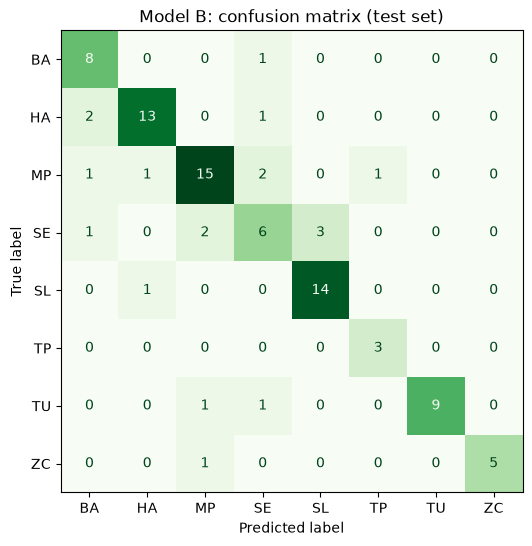

In [15]:
print(classification_report(y_test, preds_b, target_names=class_codes, digits=3))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds_b), display_labels=class_codes).plot(
    ax=ax, cmap="Greens", colorbar=False)
ax.set_title("Model B: confusion matrix (test set)")
plt.show()

### ROC curves (one-vs-rest)

For each pest, the ROC curve compares "this pest" against "all other pests" at every probability threshold. The AUC is the area under that curve.

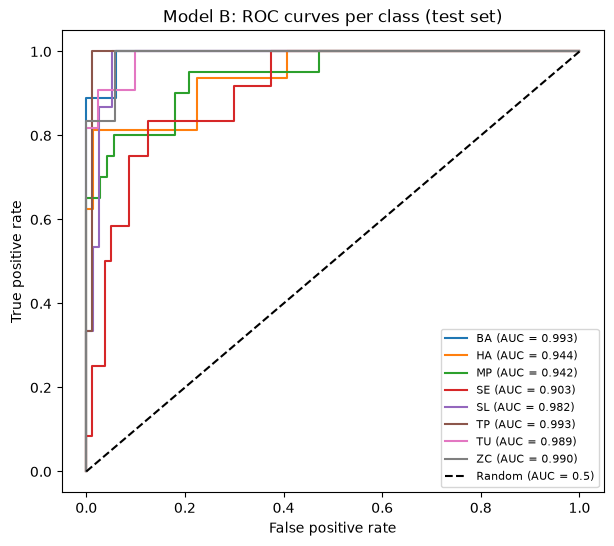

In [16]:
plt.figure(figsize=(7, 6))
for i, code_name in enumerate(class_codes):
    fpr, tpr, _ = roc_curve(y_test_oh[:, i], probs_b[:, i])
    auc_i = roc_auc_score(y_test_oh[:, i], probs_b[:, i])
    plt.plot(fpr, tpr, label=f"{code_name} (AUC = {auc_i:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC = 0.5)")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Model B: ROC curves per class (test set)")
plt.legend(loc="lower right", fontsize=8)
plt.show()

### Inspect predictions

Green titles are correct predictions, red titles are mistakes.

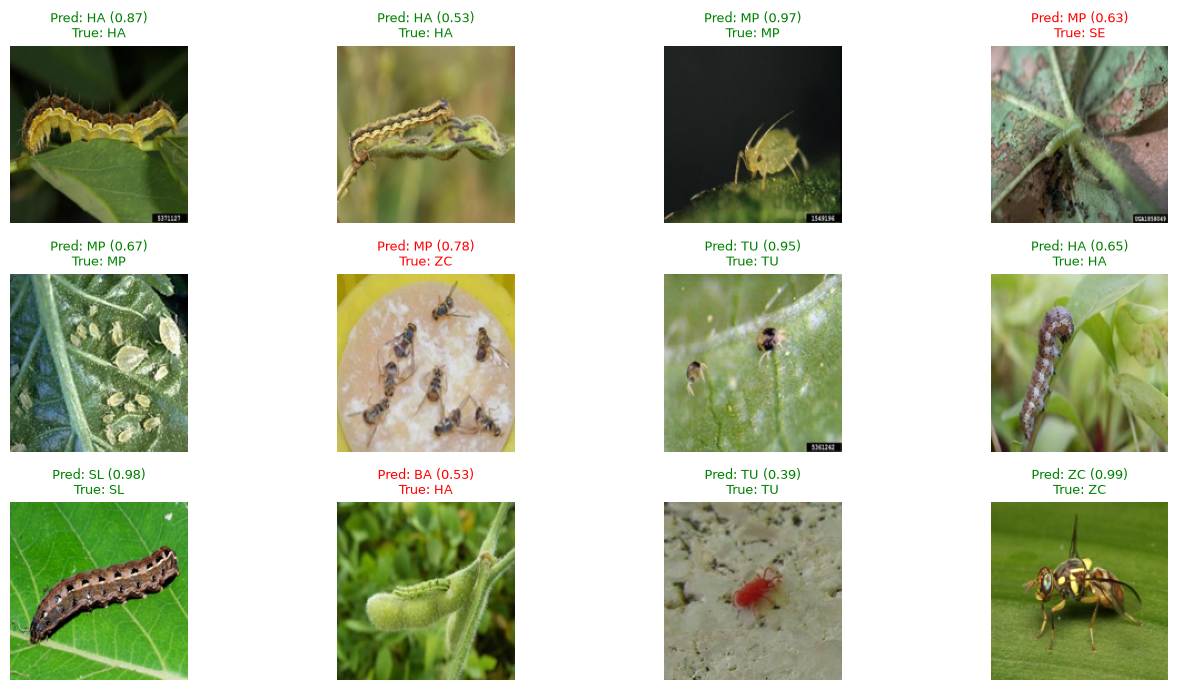

In [17]:
plt.figure(figsize=(14, 7))
for i in range(min(12, len(X_test))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[i])
    color = "green" if preds_b[i] == y_test[i] else "red"
    plt.title(f"Pred: {class_codes[preds_b[i]]} ({probs_b[i].max():.2f})\nTrue: {class_codes[y_test[i]]}",
              color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 10. Compare the two models

In [ ]:
# Hyperparameters and test-set results side by side (columns = experiments)
metric_names = ["Accuracy", "F1 (macro)", "F1 (weighted)", "AUC (macro, OvR)"]
comparison = hparams_comparison()
for m in metric_names:
    comparison.loc[len(comparison)] = [f"Test {m}"] + [f"{r[m]:.4f}" for r in [results_a, results_b]]
display(comparison.style.hide(axis="index"))

rows = [results_a, results_b]
metric_names = ["Accuracy", "F1 (macro)", "F1 (weighted)", "AUC (macro, OvR)"]

print(f"{'Model':26s}" + "".join(f"{m:>18s}" for m in metric_names))
for r in rows:
    print(f"{r['Model']:26s}" + "".join(f"{r[m]:18.4f}" for m in metric_names))

x_pos = np.arange(len(metric_names))
plt.figure(figsize=(9, 4))
plt.bar(x_pos - 0.2, [results_a[m] for m in metric_names], 0.4, label=results_a["Model"], color="lightgray")
plt.bar(x_pos + 0.2, [results_b[m] for m in metric_names], 0.4, label=results_b["Model"], color="seagreen")
plt.xticks(x_pos, metric_names)
plt.ylim(0, 1.05)
plt.ylabel("Score (test set)")
plt.title("Test-set metrics: Model A vs Model B")
plt.legend()
plt.show()

## 11. Conclusions

- Both models use **two Dense layers** as the classifier: Dense(128, ReLU) → Dense(8, Softmax).
- **Model A** (Dense layers on raw pixels) is weak. Dense layers alone cannot learn visual features from only ~430 training images.
- **Model B** keeps the same two Dense layers but gives them features from a pretrained MobileNetV2. Accuracy, macro F1 and AUC all improve a lot (see the table above).
- **Accuracy** gives the overall picture, **macro F1** checks that rare pests are also recognised, and **AUC** checks that the predicted probabilities are reliable.

**Limitations and next steps**
- The dataset is small (609 images), and some classes have only 3–6 test images, so the scores vary between runs. K-fold cross-validation would give a more stable estimate.
- Fine-tuning the top layers of MobileNetV2, or collecting more field photos, would probably improve results further.
- Images come from databases and web searches; real farm photos (leaves, poor lighting) may be harder.

**Reference:** Huang, M.-L., & Chuang, T.-C. (2020). *A database of eight common tomato pest images*. Mendeley Data, V1. https://doi.org/10.17632/s62zm6djd2.1